In [3]:
from google.colab import files
from pathlib import Path
import pandas as pd
import joblib

print("1. Chọn file dữ liệu Excel")
files.upload()

print("2. Chọn 2 file mô hình")
files.upload()

print("3. Chọn 2 file kết quả")
files.upload()

required_files = [
    "final_labeled_clean_v3.xlsx",
    "best_bow_svm.joblib",
    "best_tfidf_svm.joblib",
    "best_bow_metrics.csv",
    "best_tfidf_metrics.csv"
]

for filename in required_files:
    print(filename, "OK" if Path(filename).exists() else "THIẾU")


1. Chọn file dữ liệu Excel


Saving final_labeled_clean_v3.xlsx to final_labeled_clean_v3 (1).xlsx
2. Chọn 2 file mô hình


Saving best_bow_metrics.csv to best_bow_metrics.csv
Saving best_bow_svm.joblib to best_bow_svm.joblib
3. Chọn 2 file kết quả


Saving best_tfidf_metrics.csv to best_tfidf_metrics.csv
Saving best_tfidf_svm.joblib to best_tfidf_svm.joblib
final_labeled_clean_v3.xlsx OK
best_bow_svm.joblib OK
best_tfidf_svm.joblib OK
best_bow_metrics.csv OK
best_tfidf_metrics.csv OK


In [4]:
bow = pd.read_csv("best_bow_metrics.csv", index_col=0)
tfidf = pd.read_csv("best_tfidf_metrics.csv", index_col=0)

labels = ["Negative", "Neutral", "Positive"]

comparison = pd.DataFrame({
    "Label": labels,
    "BoW Precision": bow.loc[labels, "precision"].values,
    "TF-IDF Precision": tfidf.loc[labels, "precision"].values,
    "BoW Recall": bow.loc[labels, "recall"].values,
    "TF-IDF Recall": tfidf.loc[labels, "recall"].values,
    "BoW F1": bow.loc[labels, "f1-score"].values,
    "TF-IDF F1": tfidf.loc[labels, "f1-score"].values
})

display(comparison.round(4))

print("Macro F1 (OOF):")
print("BoW:", round(bow.loc["macro avg", "f1-score"], 4))
print("TF-IDF:", round(tfidf.loc["macro avg", "f1-score"], 4))


,Label,BoW Precision,TF-IDF Precision,BoW Recall,TF-IDF Recall,BoW F1,TF-IDF F1
0,Negative,0.5000,0.5033,0.4034,0.5186,0.4465,0.5109
1,Neutral,0.4785,0.5686,0.6029,0.4971,0.5335,0.5305
2,Positive,0.7949,0.7856,0.7686,0.8125,0.7815,0.7988


Macro F1 (OOF):
BoW: 0.5872
TF-IDF: 0.6134


In [7]:
from sklearn.model_selection import train_test_split

df = pd.read_excel("final_labeled_clean_v3.xlsx")

df.columns = df.columns.str.strip()

df = df[["Clean Text", "Final Label"]]
df = df.rename(columns={
    "Clean Text": "text",
    "Final Label": "label"
})

X = df["text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=18
)

# 5. Kiểm tra
print("Train:", len(X_train))
print("Test:", len(X_test))
print("\nPhân bố nhãn Test:")
print(y_test.value_counts())


Train: 1669
Test: 418

Phân bố nhãn Test:
label
Positive    256
Neutral      88
Negative     74
Name: count, dtype: int64


In [8]:
import joblib
from sklearn.metrics import classification_report, f1_score

bow_model = joblib.load("best_bow_svm.joblib")
tfidf_model = joblib.load("best_tfidf_svm.joblib")

y_pred_bow = bow_model.predict(X_test)
y_pred_tfidf = tfidf_model.predict(X_test)

print("=== BoW + SVM - TEST ===")
print(classification_report(
    y_test, y_pred_bow, digits=4
))

print("=== TF-IDF + SVM - TEST ===")
print(classification_report(
    y_test, y_pred_tfidf, digits=4
))

print("=== TEST MACRO F1 ===")
print("BoW:", round(
    f1_score(y_test, y_pred_bow, average="macro"), 4
))
print("TF-IDF:", round(
    f1_score(y_test, y_pred_tfidf, average="macro"), 4
))


=== BoW + SVM - TEST ===
              precision    recall  f1-score   support

    Negative     0.5500    0.4459    0.4925        74
     Neutral     0.5263    0.5682    0.5464        88
    Positive     0.7947    0.8164    0.8054       256

    accuracy                         0.6986       418
   macro avg     0.6237    0.6102    0.6148       418
weighted avg     0.6949    0.6986    0.6955       418

=== TF-IDF + SVM - TEST ===
              precision    recall  f1-score   support

    Negative     0.5750    0.6216    0.5974        74
     Neutral     0.5857    0.4659    0.5190        88
    Positive     0.8060    0.8438    0.8244       256

    accuracy                         0.7249       418
   macro avg     0.6556    0.6438    0.6469       418
weighted avg     0.7187    0.7249    0.7199       418

=== TEST MACRO F1 ===
BoW: 0.6148
TF-IDF: 0.6469


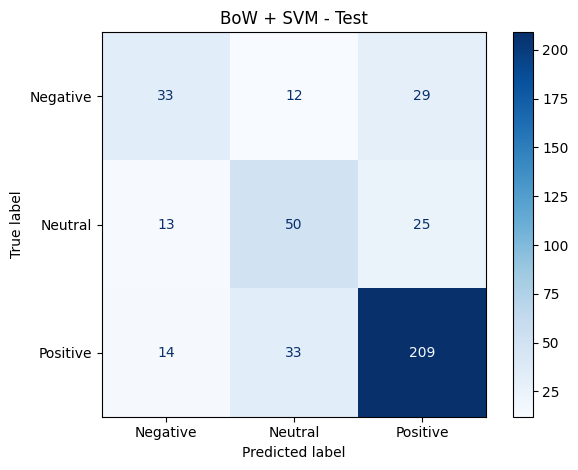

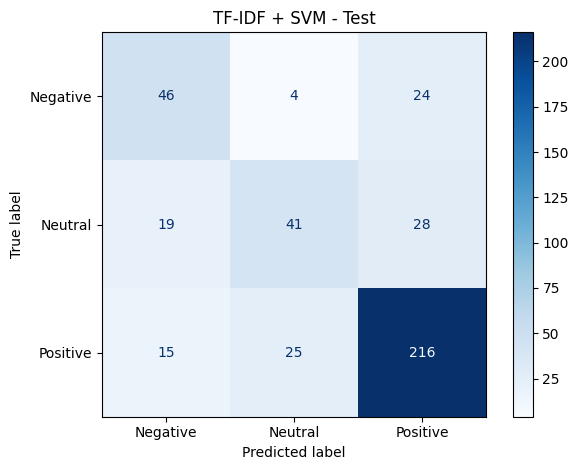

In [9]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = ["Negative", "Neutral", "Positive"]

# 1. Confusion Matrix - BoW
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_bow,
    labels=labels,
    cmap="Blues",
    values_format="d"
)

plt.title("BoW + SVM - Test")
plt.tight_layout()
plt.savefig("bow_test_confusion_matrix.png", dpi=300)
plt.show()

# 2. Confusion Matrix - TF-IDF
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tfidf,
    labels=labels,
    cmap="Blues",
    values_format="d"
)

plt.title("TF-IDF + SVM - Test")
plt.tight_layout()
plt.savefig("tfidf_test_confusion_matrix.png", dpi=300)
plt.show()


In [10]:

import pandas as pd
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

predictions = {
    "BoW + SVM": y_pred_bow,
    "TF-IDF + SVM": y_pred_tfidf
}

# 1. Bảng so sánh tổng thể
summary = []

for name, y_pred in predictions.items():
    summary.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Precision": precision_score(
            y_test, y_pred, average="macro"
        ),
        "Macro Recall": recall_score(
            y_test, y_pred, average="macro"
        ),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro"
        )
    })

summary_df = pd.DataFrame(summary)

# 2. Bảng kết quả từng nhãn
details = []

for name, y_pred in predictions.items():
    report = classification_report(
        y_test, y_pred, output_dict=True
    )

    for label in ["Negative", "Neutral", "Positive"]:
        details.append({
            "Model": name,
            "Label": label,
            "Precision": report[label]["precision"],
            "Recall": report[label]["recall"],
            "F1": report[label]["f1-score"],
            "Support": report[label]["support"]
        })

details_df = pd.DataFrame(details)

# 3. Hiển thị
print("=== MODEL COMPARISON ===")
display(summary_df.round(4))

print("=== PER-CLASS METRICS ===")
display(details_df.round(4))

# 4. Lưu hai bảng
summary_df.to_csv(
    "test_model_comparison.csv",
    index=False
)

details_df.to_csv(
    "test_class_metrics.csv",
    index=False
)

print("Đã lưu kết quả Test.")


=== MODEL COMPARISON ===


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,BoW + SVM,0.6986,0.6237,0.6102,0.6148
1,TF-IDF + SVM,0.7249,0.6556,0.6438,0.6469


=== PER-CLASS METRICS ===


,Model,Label,Precision,Recall,F1,Support
0,BoW + SVM,Negative,0.5500,0.4459,0.4925,74.0
1,BoW + SVM,Neutral,0.5263,0.5682,0.5464,88.0
2,BoW + SVM,Positive,0.7947,0.8164,0.8054,256.0
3,TF-IDF + SVM,Negative,0.5750,0.6216,0.5974,74.0
4,TF-IDF + SVM,Neutral,0.5857,0.4659,0.5190,88.0
5,TF-IDF + SVM,Positive,0.8060,0.8438,0.8244,256.0


Đã lưu kết quả Test.
